# Q4-Q5 - Fresh inference and genuine errors
The same selected checkpoint and preprocessing serve the API and Grad-CAM.

In [1]:
from pathlib import Path
import sys, json
PROJECT = Path.cwd()
if PROJECT.name == 'notebooks': PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT / 'src'))
from fabric_inspector.common import read_json
from IPython.display import display, Image as DisplayImage, Markdown
import pandas as pd
def read(path): return read_json(PROJECT / path)
def figure(path): display(DisplayImage(filename=str(PROJECT / path)))


In [2]:
import torch, os
os.environ['FABRIC_CPU_THREADS']='1'
torch.set_num_threads(1)
from fabric_inspector.serving.predictor import Predictor
from fabric_inspector.data.manifest import load_manifest
predictor=Predictor(PROJECT/'artifacts/serving-bundle.json')
sample,rows,root=load_manifest(PROJECT/'data/sample-manifests/split.json',verify_files=True)
row=next(r for r in rows if r['split']=='val')
result=predictor.predict((root/row['image_path']).read_bytes())
display(result)

{'class': 'defect_free',
 'defect_score': 0.5182110667228699,
 'score_kind': 'uncalibrated_model_score',
 'recommendation': 'routine_inspection',
 'model_version': '8726ee0f5dfb',
 'run_id': 'ann-search-018',
 'provenance': 'RAW-FABRID_V1',
 'model_inference_ms': 10.630682000055458,
 'device': 'cpu',
 'classification_threshold': 0.8952339208126068,
 'recommendation_cutoffs': {'low': 0.8447646290063858,
  'high': 0.9988340735435486},
 'input_checks': {'mean_gray': 148.86575317382812,
  'std_gray': 42.67395303156768,
  'ood_detection': 'Not implemented or claimed'},
 'limitations': 'Patch-level decision support only. Unseen fabrics, phone lighting, blur and tiny defects can cause errors. The inspector decides.',
 'request_processing_ms': 16.68837900001563}

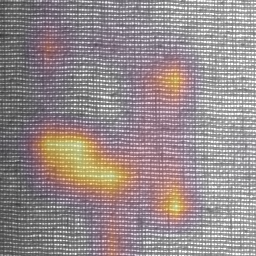

{'area_fraction': 0.0999908447265625,
 'seed': 42,
 'original_defect_logit': 0.0728764683008194,
 'logit_drops': {'top': 0.9650546461343765,
  'low': 1.0490381866693497,
  'random': -0.1639978140592575},
 'top_minus_random_drop': 1.129052460193634,
 'top_minus_low_drop': -0.08398354053497314,
 'degenerate_zero_cam': False,
 'interpretation': 'More positive top-region drop than controls supports sensitivity; no causal claim'}

In [3]:
from PIL import Image
from fabric_inspector.data.images import preprocess
from fabric_inspector.explainability.gradcam import gradcam,overlay,occlusion_check
image=Image.open(root/row['image_path']).convert('L')
tensor=preprocess(image,predictor.metadata['preprocessing']).unsqueeze(0).to(predictor.device)
cam=gradcam(predictor.model,tensor)
assert cam.shape==(256,256)
display(overlay(image,cam))
display(occlusion_check(predictor.model,tensor,cam))

**Error 1: false negative** - This genuine false negative has ground-truth label 1 and prediction 0; score 0.790539 versus validation-frozen cutoff 0.895234. The publisher mask covers 103 pixels (0.157%). Equal-area top/low/random occlusion changes the defect logit by +1.591740/+2.704260/+0.498417. This case does not support stronger sensitivity of the highlighted region than both controls. Mean-fill perturbation may create unnatural weave; the map does not identify a causal production fault or establish a certified defect boundary.

Visual inspection: The original is predominantly repeating horizontal weave. The publisher foreground is a very small region at the bottom edge toward the right, whereas the brightest Grad-CAM region lies higher in the lower-right interior. The maximum misses the mask and the mask receives 0.00134% of total attribution, below its 0.15717% uniform-area reference. This is consistent with poor attention to tiny boundary evidence, but does not isolate downsampling as the cause. The 0.790539 score falls below the frozen 0.895234 cutoff. Top-region deletion reduces the defect logit, yet low-attribution deletion reduces it more (2.704260 versus 1.591740); the explanation therefore fails the stronger-than-both-controls sensitivity check. A future study could test boundary-preserving features on new validation groups, without changing this evaluated model.

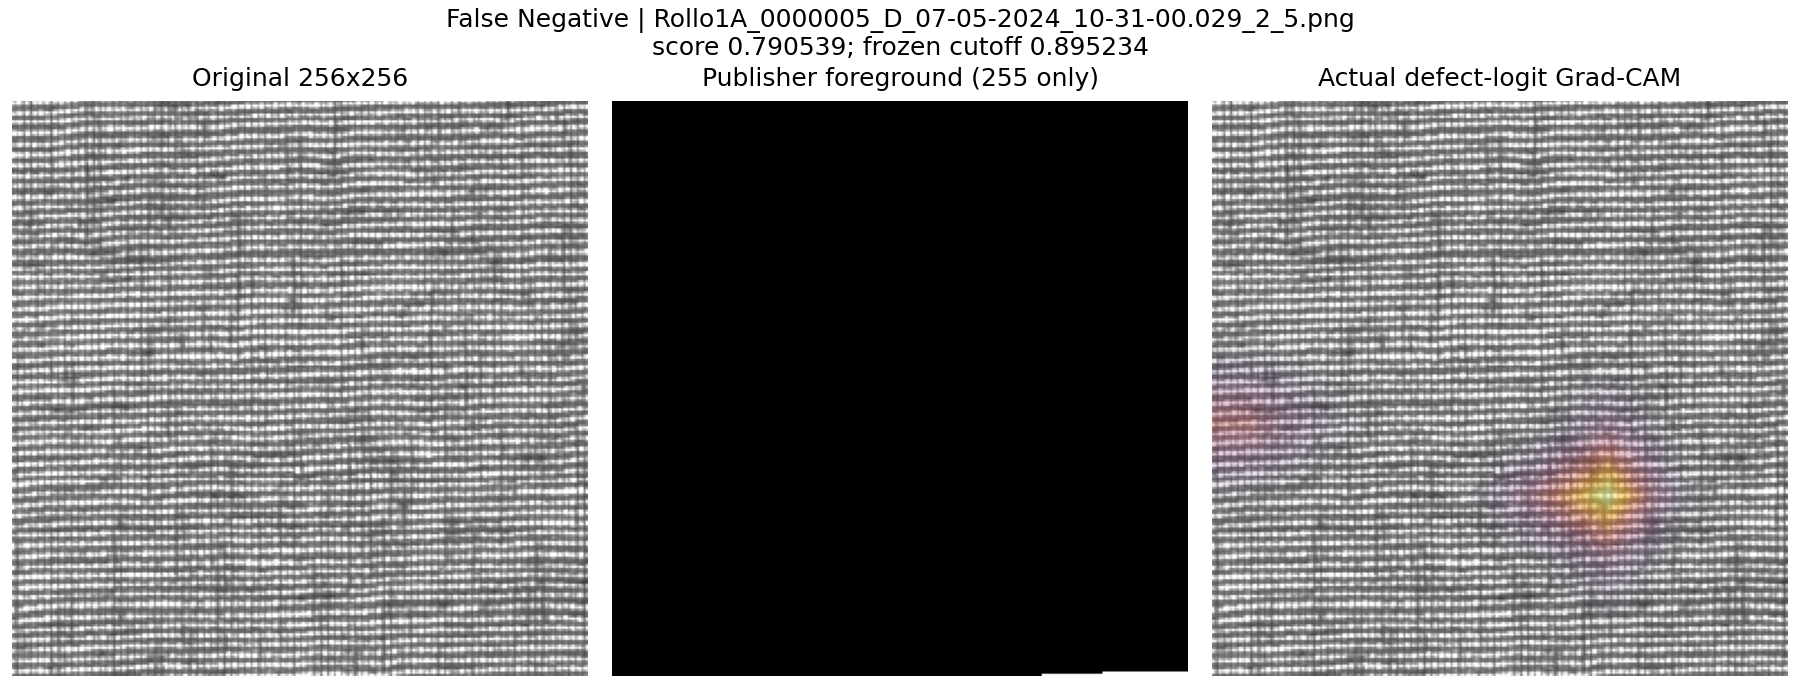

{'area_fraction': 0.0999908447265625,
 'seed': 42,
 'original_defect_logit': 1.3281800746917725,
 'logit_drops': {'top': 1.5917399227619171,
  'low': 2.7042598724365234,
  'random': 0.49841707944869995},
 'top_minus_random_drop': 1.0933228433132172,
 'top_minus_low_drop': -1.1125199496746063,
 'degenerate_zero_cam': False,
 'interpretation': 'More positive top-region drop than controls supports sensitivity; no causal claim'}

**Error 2: false negative** - This genuine false negative has ground-truth label 1 and prediction 0; score 0.204645 versus validation-frozen cutoff 0.895234. The publisher mask covers 1764 pixels (2.692%). Equal-area top/low/random occlusion changes the defect logit by -0.427480/-0.421962/-0.641229. This case does not support stronger sensitivity of the highlighted region than both controls. Mean-fill perturbation may create unnatural weave; the map does not identify a causal production fault or establish a certified defect boundary.

Visual inspection: The publisher annotation traces an irregular narrow region down the left edge. The original shows subtle left-edge weave/intensity variation; the coarse CAM brightens the lower left and partly overlaps the annotation. Its 21.3191% attribution mass in a 2.69165%-area mask exceeds the uniform reference, but its single maximum remains outside the exact-white mask. Spatial overlap alone does not explain the low 0.204645 score or certify a boundary. All three occlusions increase the defect logit (negative drops); top deletion is -0.427480 versus low -0.421962 and random -0.641229. Thus the highlighted region is not validated as selectively supporting the defect decision by this perturbation. The mean-fill change may itself disrupt the weave; neither a production cause nor annotation severity is established.

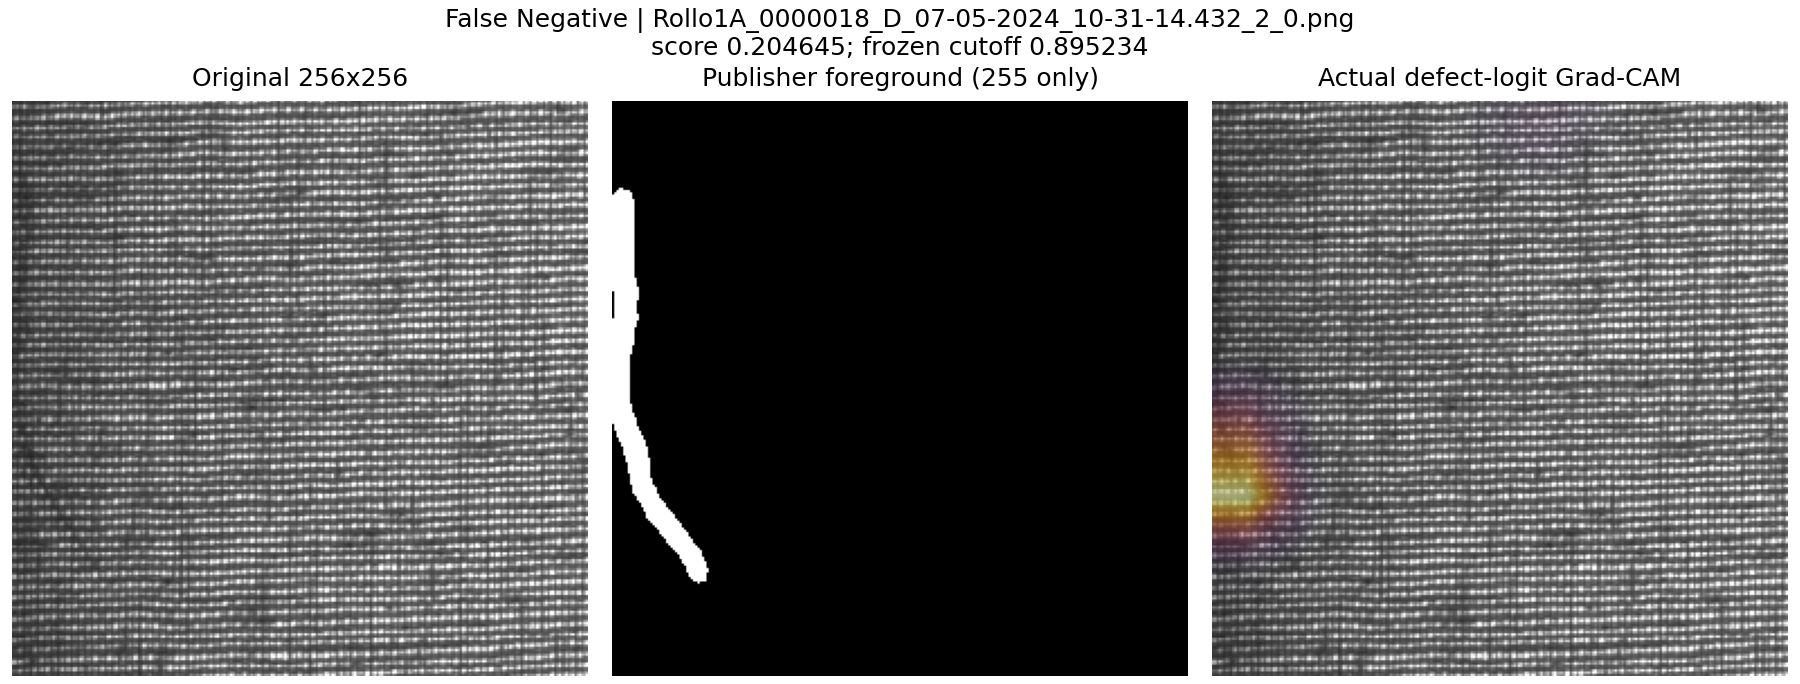

{'area_fraction': 0.0999908447265625,
 'seed': 42,
 'original_defect_logit': -1.3575118780136108,
 'logit_drops': {'top': -0.42747950553894043,
  'low': -0.42196160554885864,
  'random': -0.6412292122840881},
 'top_minus_random_drop': 0.2137497067451477,
 'top_minus_low_drop': -0.005517899990081787,
 'degenerate_zero_cam': False,
 'interpretation': 'More positive top-region drop than controls supports sensitivity; no causal claim'}

**Error 3: false positive** - This genuine false positive has ground-truth label 0 and prediction 1; score 0.925760 versus validation-frozen cutoff 0.895234. The publisher mask covers 0 pixels (0.000%). Equal-area top/low/random occlusion changes the defect logit by +2.779529/+3.000914/-0.592691. This case does not support stronger sensitivity of the highlighted region than both controls. Mean-fill perturbation may create unnatural weave; the map does not identify a causal production fault or establish a certified defect boundary.

Visual inspection: The original has regular weave and a short narrow dark vertical feature in the upper-right region. Grad-CAM peaks nearby, while the publisher foreground is empty and the explicit patch label is normal. The model score 0.925760 exceeds the frozen 0.895234 cutoff, creating a genuine false positive under the publisher target. The highlight is compatible with sensitivity to a visually distinctive texture feature, but does not establish a real unannotated defect or an incorrect publisher label. Empty-mask overlap and pointing-hit scores are undefined, not zero-quality localisation measures. Top deletion lowers the logit by 2.779529, but low-attribution deletion lowers it more (3.000914); random deletion raises it. This again fails the stronger-than-both-controls check. Independent inspector annotation would be needed before revising any label.

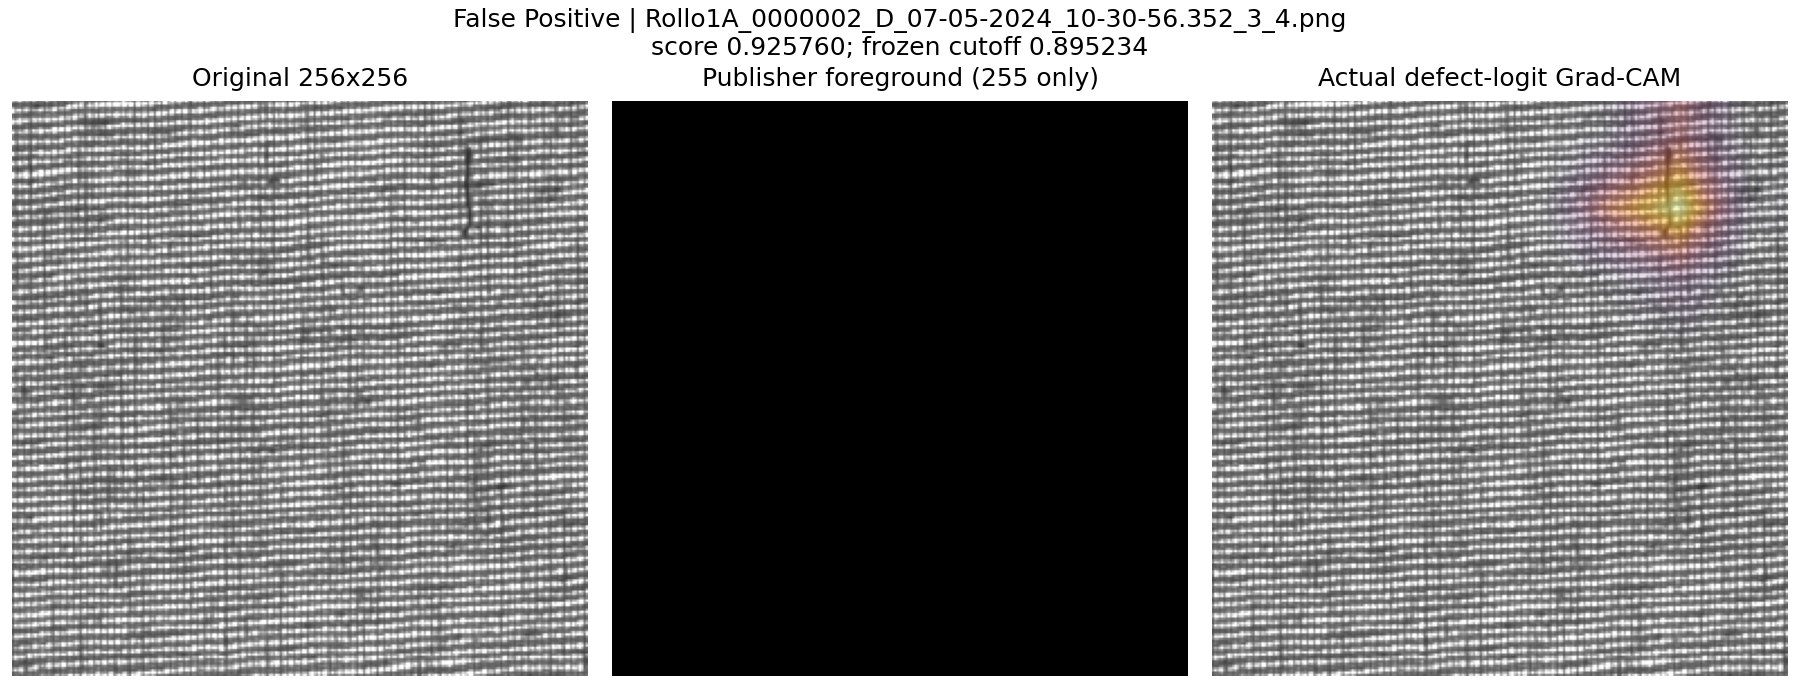

{'area_fraction': 0.0999908447265625,
 'seed': 42,
 'original_defect_logit': 2.523315906524658,
 'logit_drops': {'top': 2.7795287370681763,
  'low': 3.0009138882160187,
  'random': -0.5926909446716309},
 'top_minus_random_drop': 3.372219681739807,
 'top_minus_low_drop': -0.2213851511478424,
 'degenerate_zero_cam': False,
 'interpretation': 'More positive top-region drop than controls supports sensitivity; no causal claim'}

In [4]:
cases=read('docs/three-xai-errors.json')['cases']
assert len(cases)>=3 and all(c['incorrect'] and c['label']!=c['prediction'] for c in cases)
for case in cases:
    display(Markdown('**'+case['case_name']+'** - '+case['analysis']+'\n\nVisual inspection: '+case['visual_analysis']))
    figure(case['panel'])
    display(case['occlusion'])

In [5]:
verification=read('reports/application-verification/results.json')
assert verification['status']=='PASS'
display(verification)

{'status': 'PASS',
 'timestamp': '2026-10-12T05:47:02.611737+00:00',
 'model_version': '8726ee0f5dfb',
 'run_id': 'ann-search-018',
 'bundle': 'artifacts/serving-bundle.json',
 'http_checks': [{'check': 'readiness and static routes', 'status': 'PASS'},
  {'check': 'original grayscale PNG direct/HTTP parity',
   'status': 'PASS',
   'result': {'class': 'defect_free',
    'defect_score': 0.12496597319841385,
    'score_kind': 'uncalibrated_model_score',
    'recommendation': 'routine_inspection',
    'model_version': '8726ee0f5dfb',
    'run_id': 'ann-search-018',
    'provenance': 'RAW-FABRID_V1',
    'model_inference_ms': 10.543039999902248,
    'device': 'cpu',
    'classification_threshold': 0.8952339208126068,
    'recommendation_cutoffs': {'low': 0.8447646290063858,
     'high': 0.9988340735435486},
    'input_checks': {'mean_gray': 118.304443359375,
     'std_gray': 48.31858256334084,
     'ood_detection': 'Not implemented or claimed'},
    'limitations': 'Patch-level decision sup

Grad-CAM is a coarse defect-logit sensitivity map; it is not a segmentation output or causal proof. Equal-area top/low/random mean-fill occlusion tests sensitivity. Negative drops, zero CAMs and failures against controls are reported. Integrated Gradients depends on a reference image; LIME depends on perturbations and a local surrogate.